# Ara el que intentarem és convergir tota la informació
### Idealment passarem de n patologies a m dents a si te o no te la n patologia

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

In [ ]:
data_dir = Path("data/raw/dentex")

images_dir = (
    data_dir
    / "validation_data"
    / "quadrant_enumeration_disease"
    / "xrays"
)

json_path = data_dir / "validation_triple.json"

with open(json_path, "r") as f:
    data = json.load(f)



print(f"Imatges: {len(data['images'])}")
print(f"Anotacions: {len(data['annotations'])}")
print(data.keys())


#definim les patologies en diccionaris 

quadrants = {x["id"]: x["name"] for x in data["categories_1"]}
teeth = {x["id"]: x["name"] for x in data["categories_2"]}
diagnoses = {x["id"]: x["name"] for x in data["categories_3"]}



Imatges: 50
Anotacions: 182
dict_keys(['images', 'annotations', 'categories_1', 'categories_2', 'categories_3'])
{0: 'Impacted', 1: 'Caries', 2: 'Periapical Lesion', 3: 'Deep Caries'}


In [30]:
import pandas as pd

# Fila per cada imatge
labels_df = pd.DataFrame(data["images"])[["id", "file_name","height", "width"]]
#canviarem el nom de id, per image_id, per a que sigui més clar
labels_df.rename(columns = {"id": "image_id"}, inplace = True)

print(labels_df.head())# Ara definim les etiquetes de les patologies

label_names = {
    0: "has_impacted",
    1: "has_caries",
    2: "has_periapical_lesion",
    3: "has_deep_caries"
}

for label in label_names.values():
    labels_df[label] = 0


#i ara hem d'omplir les etiquetes cada cop que tenim el diagnostic corresponent
# només m'interessa la categoria 3, que és la que ens diu quina patologia és

for ann in data["annotations"]:
    image_id = ann["image_id"]
    diagnosis_id = ann["category_id_3"]
    label_name = label_names[diagnosis_id]
    labels_df.loc[labels_df["image_id"] == image_id, label_name] = 1

labels_df.head(10)

   image_id   file_name  height  width
0         1  val_15.png    1316   2892
1         2  val_38.png    1316   2942
2         3  val_33.png    1316   2987
3         4  val_30.png    1504   2872
4         5   val_5.png    1316   2970


,image_id,file_name,height,width,has_impacted,has_caries,has_periapical_lesion,has_deep_caries
0,1,val_15.png,1316,2892,1,1,0,0
1,2,val_38.png,1316,2942,1,0,1,0
2,3,val_33.png,1316,2987,0,1,0,1
3,4,val_30.png,1504,2872,0,1,1,1
4,5,val_5.png,1316,2970,0,1,0,0
5,6,val_21.png,1316,2860,1,1,0,1
6,7,val_39.png,1504,2804,0,0,0,1
7,8,val_46.png,1316,2883,0,1,0,0
8,9,val_20.png,1316,2967,0,1,0,0
9,10,val_3.png,1504,2872,0,0,0,1


In [39]:
diagnosis_columns = list(label_names.values())

print("Imatges per diagnòstic:")
display(labels_df[diagnosis_columns].sum().sort_values(ascending=False))

labels_df["n_diagnoses"] = labels_df[diagnosis_columns].sum(axis=1)

print("\nNombre de diagnòstics diferents per imatge (Numero de diagnostics -> imatges que ho compleixen):")
display(labels_df["n_diagnoses"].value_counts().sort_index())

Imatges per diagnòstic:


has_caries               37
has_deep_caries          20
has_impacted             16
has_periapical_lesion     7
dtype: int64


Nombre de diagnòstics diferents per imatge (Numero de diagnostics -> imatges que ho compleixen):


n_diagnoses
0     4
1    20
2    20
3     4
4     2
Name: count, dtype: int64

# compto el nombre de patologies que tenim en total

In [41]:
annotation_counts = (
    pd.DataFrame(data["annotations"])["category_id_3"]
    .map(diagnoses)
    .value_counts()
)

print("Nombre total de dents/troballes anotades:")
display(annotation_counts)



Nombre total de dents/troballes anotades:


category_id_3
Caries               101
Impacted              40
Deep Caries           32
Periapical Lesion      9
Name: count, dtype: int64

In [42]:
def draw_annotations(ax, file_name):
    image_info = next(
        img for img in data["images"]
        if img["file_name"] == file_name
    )

    image_id = image_info["id"]

    image_annotations = [
        ann for ann in data["annotations"]
        if ann["image_id"] == image_id
    ]

    image = Image.open(images_dir / file_name)
    ax.imshow(image, cmap="gray")

    for ann in image_annotations:
        x, y, width, height = ann["bbox"]

        ax.add_patch(
            Rectangle(
                (x, y), width, height,
                linewidth=2,
                edgecolor="lime",
                facecolor="none"
            )
        )

        fdi = quadrants[ann["category_id_1"]] + teeth[ann["category_id_2"]]
        diagnosis = diagnoses[ann["category_id_3"]]

        ax.text(
            x, y - 10,
            f"{fdi} — {diagnosis}",
            color="black",
            fontsize=8,
            bbox={"facecolor": "lime", "alpha": 0.85, "pad": 2}
        )

    ax.set_title(file_name)
    ax.axis("off")

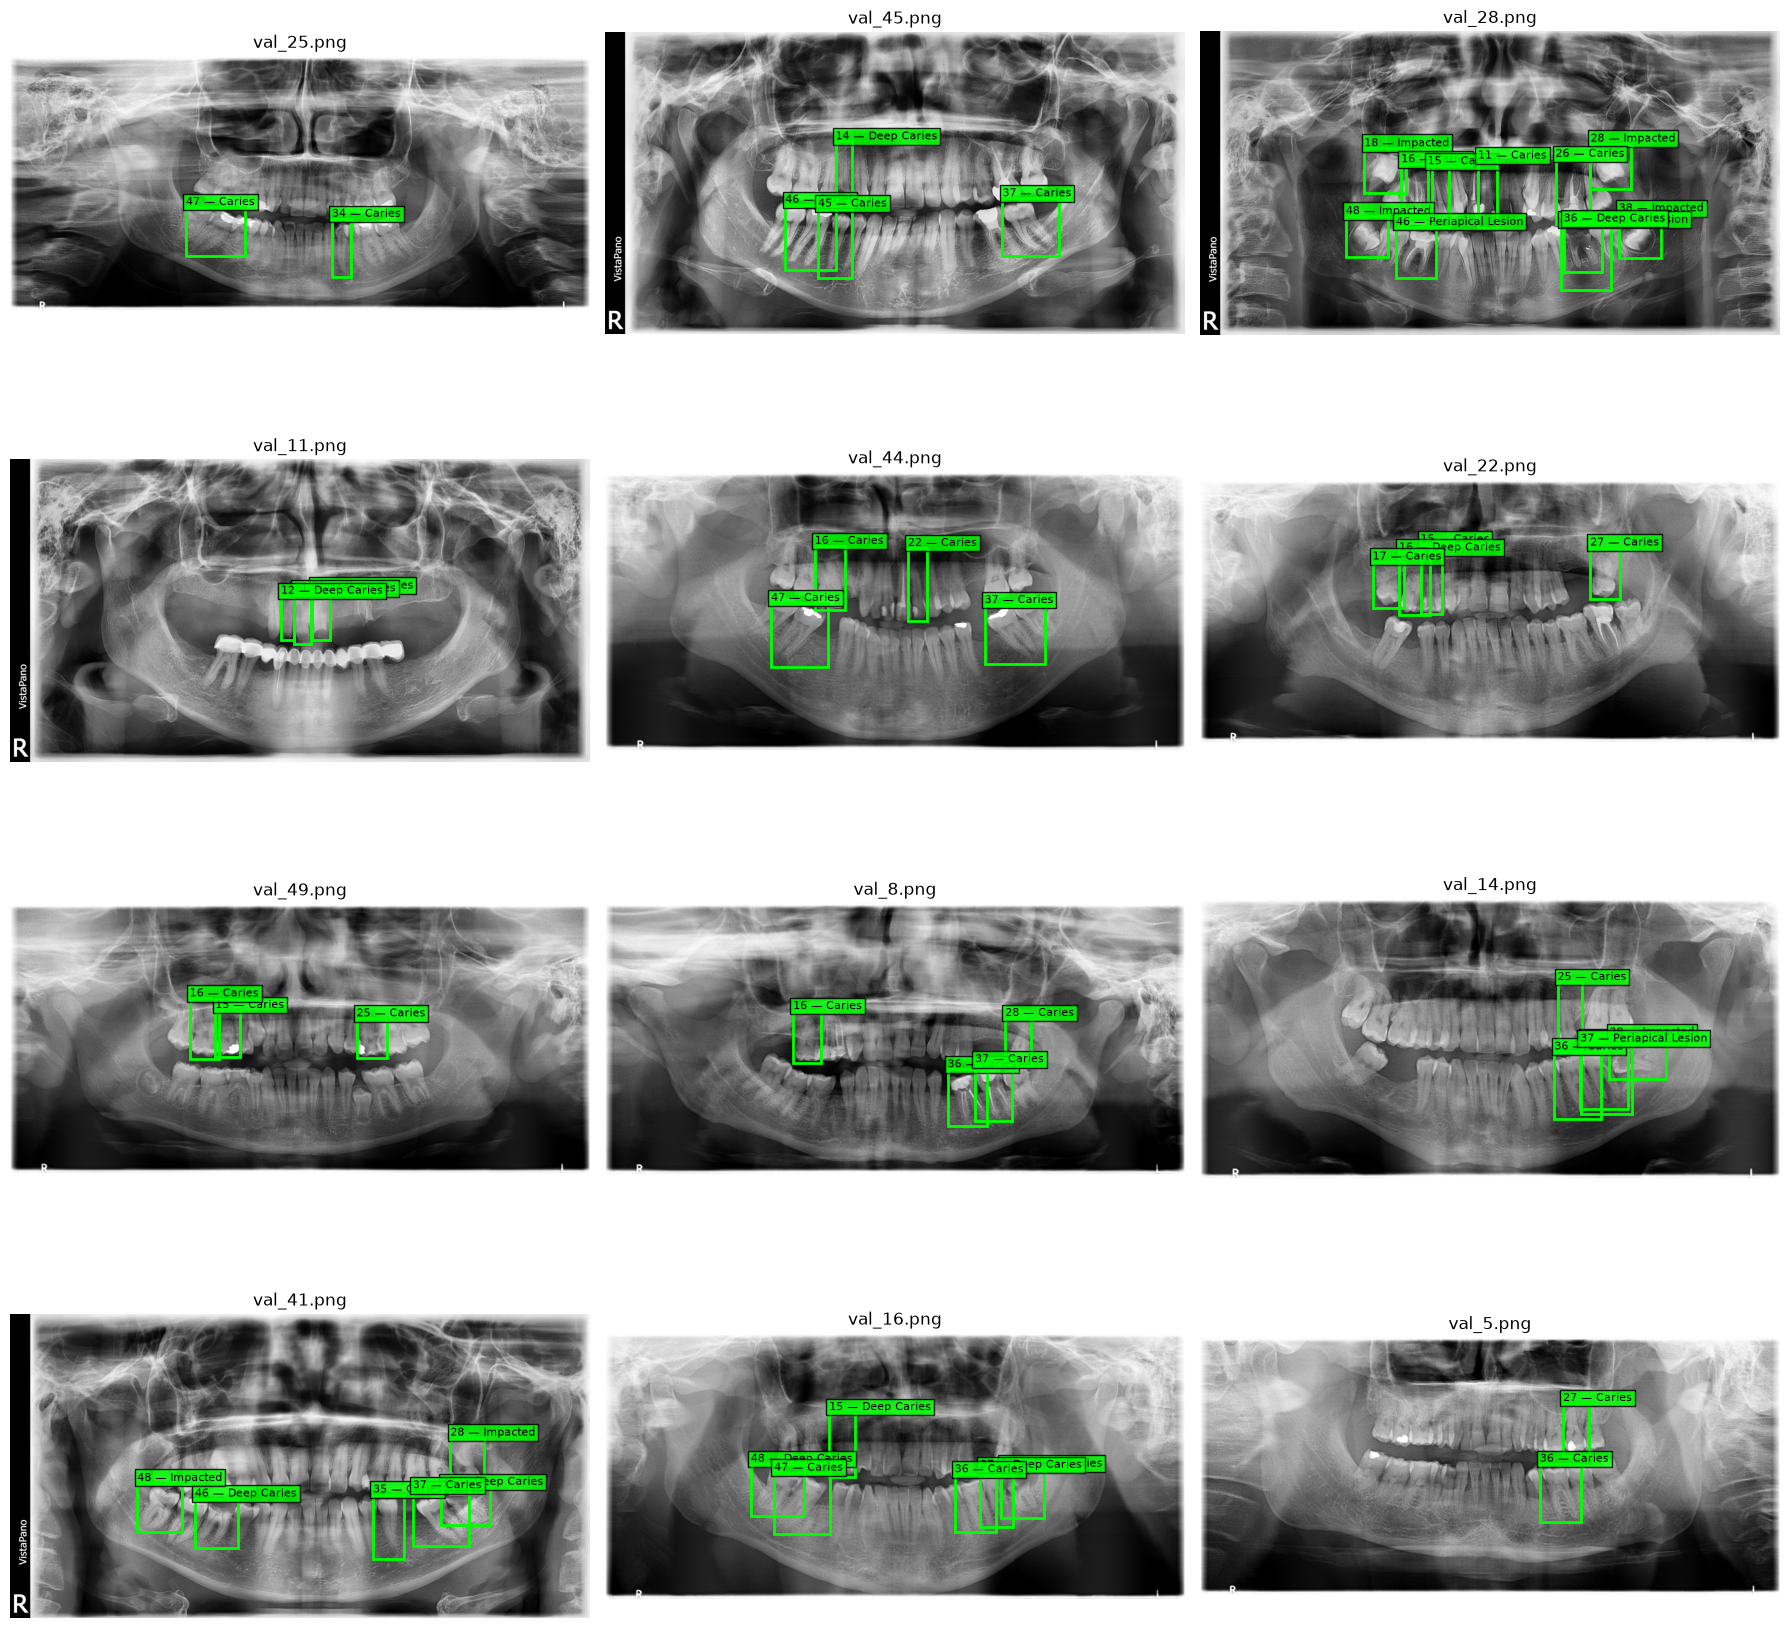

In [43]:
sample_files = labels_df.sample(12, random_state=42)["file_name"].tolist()

fig, axes = plt.subplots(4, 3, figsize=(18, 18))
axes = axes.flatten()

for ax, file_name in zip(axes, sample_files):
    draw_annotations(ax, file_name)

plt.tight_layout()
plt.show()